<a href="https://colab.research.google.com/github/lamaljalal/NLP/blob/main/Lab10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

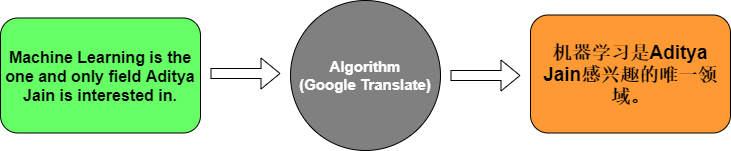

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.0000e+00 - loss: 2.4852 - val_accuracy: 0.0000e+00 - val_loss: 2.4884
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.5714 - loss: 2.4771 - val_accuracy: 0.0000e+00 - val_loss: 2.4906
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.5714 - loss: 2.4688 - val_accuracy: 0.0000e+00 - val_loss: 2.4930
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.5714 - loss: 2.4598 - val_accuracy: 0.0000e+00 - val_loss: 2.4957
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.5714 - loss: 2.4499 - val_accuracy: 0.0000e+00 - val_loss: 2.4987
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.5714 - loss: 2.4384 - val_accuracy: 0.0000e+00 - val_loss: 2.5021
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.5714 - loss: 2.4250 - val_accuracy: 0.0000e+00 - val_loss: 2.5059
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.5714 - loss: 2.4092 - val_accur

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step
Input: How are you?
Translation: ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**1. Embedding layer:** Converts each integer word ID into a dense, trainable vector that captures useful word features.

**3. Encoder LSTM:** Reads the English input sequence and summarizes its information in a learned representation.

**5. Decoder LSTM:** Uses that representation to generate a sequence of hidden states for the French output words.

**8. Softmax:** Converts output scores into a probability distribution over French vocabulary tokens at each output position, allowing the model to select a word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [11]:

# ============================================================
# TASK 2: English-to-French Machine Translation
# Improved Google Colab Version
# ============================================================

!pip -q install transformers sentencepiece sacrebleu

import io
import zipfile
import re
import os
import numpy as np
import pandas as pd
import torch

from google.colab import files
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from sacrebleu.metrics import BLEU, CHRF

# ------------------------------------------------------------
# 1. Upload Dataset
# ------------------------------------------------------------

MODEL_ID = "Helsinki-NLP/opus-mt-en-fr"

print("Upload English-French CSV or ZIP dataset:")
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload your dataset.")

# ------------------------------------------------------------
# 2. Read CSV or ZIP
# ------------------------------------------------------------

def csv_candidates(items):
    for filename, content in items.items():

        if filename.lower().endswith(".csv"):
            yield filename, content

        elif filename.lower().endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(content)) as archive:
                for member in archive.namelist():
                    if (
                        member.lower().endswith(".csv")
                        and not member.startswith("__MACOSX")
                    ):
                        yield member, archive.read(member)


def read_parallel(name, content):

    for encoding in ("utf-8-sig", "utf-8", "latin1"):
        for sep in (",", "\t", ";"):
            for header in (0, None):

                try:
                    data = pd.read_csv(
                        io.BytesIO(content),
                        sep=sep,
                        encoding=encoding,
                        header=header,
                        on_bad_lines="skip",
                        dtype=str
                    )

                    if data.shape[1] < 2 or len(data) < 5:
                        continue

                    normalized = [
                        re.sub("[^a-z]", "", str(c).lower())
                        for c in data.columns
                    ]

                    english = next(
                        (
                            i for i, c in enumerate(normalized)
                            if c in (
                                "english", "en", "eng",
                                "englishsentence", "englishtext",
                                "source"
                            )
                        ),
                        None
                    )

                    french = next(
                        (
                            i for i, c in enumerate(normalized)
                            if c in (
                                "french", "fr", "fra",
                                "frenchsentence", "frenchtext",
                                "target"
                            )
                        ),
                        None
                    )

                    if english is None or french is None:
                        if header is not None:
                            continue
                        english, french = 0, 1

                    pairs = data.iloc[:, [english, french]].copy()
                    pairs.columns = ["english", "french"]

                    pairs = pairs.dropna().drop_duplicates()

                    pairs["english"] = pairs["english"].str.strip()
                    pairs["french"] = pairs["french"].str.strip()

                    pairs = pairs[
                        (pairs.english.str.len() > 1)
                        & (pairs.french.str.len() > 1)
                    ]

                    pairs = pairs[
                        pairs.english.str.contains(
                            "[A-Za-z]", regex=True
                        )
                        & pairs.french.str.contains(
                            "[A-Za-zÀ-ÿ]", regex=True
                        )
                    ]

                    if len(pairs) < 5:
                        continue

                    if (
                        header is None
                        and pairs.iloc[0].english.lower()
                        in ("english", "en")
                    ):
                        pairs = pairs.iloc[1:]

                    return pairs.reset_index(drop=True)

                except (
                    UnicodeError,
                    ValueError,
                    pd.errors.ParserError
                ):
                    pass

    return None


pairs = None

for name, content in csv_candidates(uploaded):

    pairs = read_parallel(name, content)

    if pairs is not None:
        print("Loaded:", name)
        print("Valid pairs:", len(pairs))
        break

if pairs is None:
    raise ValueError(
        "Could not read English-French sentence pairs."
    )

print("\nDataset Preview:")
print(pairs.head())

# ------------------------------------------------------------
# 3. Prepare Test Dataset
# ------------------------------------------------------------

test = pairs.sample(
    n=min(100, len(pairs)),
    random_state=42
).reset_index(drop=True)

print("\nTest samples:", len(test))

# ------------------------------------------------------------
# 4. Load Pretrained Translation Model
# ------------------------------------------------------------

device = "cuda" if torch.cuda.is_available() else "cpu"

print("\nUsing device:", device)
print("Loading translation model...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_ID
).to(device)

model.eval()

print("Model loaded successfully!")

# ------------------------------------------------------------
# 5. Translation Function
# ------------------------------------------------------------

def translate_batch(sentences, batch_size=8):

    predictions = []

    for start in range(0, len(sentences), batch_size):

        batch = sentences[start:start + batch_size]

        tokens = tokenizer(
            batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=128
        ).to(device)

        with torch.inference_mode():

            ids = model.generate(
                **tokens,
                max_new_tokens=128,
                num_beams=4,
                early_stopping=True
            )

        translations = tokenizer.batch_decode(
            ids,
            skip_special_tokens=True
        )

        predictions.extend(translations)

    return predictions

# ------------------------------------------------------------
# 6. Translate Test Dataset
# ------------------------------------------------------------

print("\nTranslating test sentences...")

predictions = translate_batch(
    test.english.tolist()
)

references = test.french.tolist()

# ------------------------------------------------------------
# 7. Evaluate Translation Quality
# ------------------------------------------------------------

bleu = BLEU().corpus_score(
    predictions,
    [references]
).score

chrf = CHRF().corpus_score(
    predictions,
    [references]
).score

print("\n===== Evaluation Results =====")
print("SacreBLEU Score:", round(bleu, 2))
print("chrF Score:", round(chrf, 2))

# ------------------------------------------------------------
# 8. Display Translation Examples
# ------------------------------------------------------------

print("\n===== Translation Examples =====")

for i in range(min(5, len(test))):

    print("\nEnglish:", test.english.iloc[i])
    print("Reference French:", references[i])
    print("Predicted French:", predictions[i])
    print("-" * 50)

# ------------------------------------------------------------
# 9. E-Commerce Translation Examples
# ------------------------------------------------------------

print("\n===== E-Commerce Translation Examples =====")

examples = [
    "Add this item to your cart.",
    "Free shipping on orders over fifty dollars.",
    "Thank you for your review.",
    "Your order has been shipped.",
    "This product is currently unavailable."
]

results = translate_batch(examples)

for english, french in zip(examples, results):
    print("\nEnglish:", english)
    print("French:", french)

# ------------------------------------------------------------
# 10. Save Results
# ------------------------------------------------------------

output = test.copy()
output["predicted_french"] = predictions

output.to_csv(
    "/content/translation_results.csv",
    index=False
)

# ------------------------------------------------------------
# 11. Save Model
# ------------------------------------------------------------

model.save_pretrained(
    "/content/english_french_translator"
)

tokenizer.save_pretrained(
    "/content/english_french_translator"
)

print("\nModel saved successfully!")
print("Results saved successfully!")
print("Task 2 completed!")


Upload English-French CSV or ZIP dataset:


Saving eng_-french.csv to eng_-french (2).csv
Loaded: eng_-french (2).csv
Valid pairs: 175622

Dataset Preview:
                   english                  french
0  English words/sentences  French words/sentences
1                      Hi.                  Salut!
2                     Run!                 Cours !
3                     Run!                Courez !
4                     Who?                   Qui ?

Test samples: 100

Using device: cpu
Loading translation model...


config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

...

Model loaded successfully!

Translating test sentences...


[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface


===== Evaluation Results =====
SacreBLEU Score: 48.99
chrF Score: 64.14

===== Translation Examples =====

English: Take a seat.
Reference French: Prenez place !
Predicted French: Asseyez-vous.
--------------------------------------------------

English: I wish Tom the best.
Reference French: Je souhaite le meilleur à Tom.
Predicted French: Je souhaite le meilleur à Tom.
--------------------------------------------------

English: How did it all work out?
Reference French: Comment tout cela s'est-il résolu ?
Predicted French: Comment ça s'est passé ?
--------------------------------------------------

English: I've no friend to talk to about my problems.
Reference French: Je n'ai pas d'ami avec lequel je puisse m'entretenir de mes problèmes.
Predicted French: Je n'ai aucun ami à qui parler de mes problèmes.
--------------------------------------------------

English: I really like this skirt. Can I try it on?
Reference French: J'aime beaucoup cette jupe, puis-je l'essayer ?
Predicted 

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved successfully!
Results saved successfully!
Task 2 completed!


### Task 2 — Discussion

This solution uses tokenization and padding to prepare parallel English–French sentence pairs, then trains an LSTM encoder–decoder to predict French tokens. The training/validation/test split evaluates performance on held-out examples. Test loss, token-level accuracy, and five example predictions are printed when the cell runs. **Limitations:** A small LSTM trained for a few epochs is a teaching example rather than a production-quality e-commerce translator. Unknown words, long sentences, and domain-specific terminology may reduce translation quality. A larger dataset and an attention-based Transformer would generally be better for deployment.

**Dataset:** https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

**Note:** Kaggle dataset download/upload and model training require a Colab runtime and internet access. No evaluation metrics are claimed before executing the notebook.